---
## Step 0 — Import Libraries

We use NumPy and Pandas for data handling, Matplotlib for visualization,
and Scikit-learn for standardization and PCA.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print('All libraries imported successfully!')

All libraries imported successfully!


---
## Step 1 — Load the Dataset

Place `forestfires.csv` in the same folder as this notebook before running the cell.
The dataset contains 517 observations and 13 columns.

In [ ]:
forest_dataset = pd.read_csv('forestfires.csv')

print('Dataset shape:', forest_dataset.shape)
forest_dataset.head()

Dataset shape: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


---
## Step 2 — Explore Features and Burned-Area Groups

The dataset contains:
- **Numerical features:** spatial coordinates (`X`, `Y`), fire-weather indices (`FFMC`, `DMC`, `DC`, `ISI`),
  weather measurements (`temp`, `RH`, `wind`, `rain`)
- **Categorical columns:** `month` and `day`
- **Burned area:** `area`

PCA is applied only to the 10 numerical predictor features. The `area` column is not used
to calculate principal components; it is used afterward to color the scatter plot.

For easier visualization, burned area is grouped into four categories:
- No burn: `area = 0`
- Small: `0 < area <= 1`
- Medium: `1 < area <= 10`
- Large: `area > 10`

These thresholds are descriptive plotting groups, not original labels supplied by the dataset.

In [ ]:
print('Dataset information:')
print(f'Number of samples: {len(forest_dataset)}')
print(f'Number of columns: {len(forest_dataset.columns)}')
print()

features = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

print('Number of PCA features:', len(features))
print('Feature names:', features)
print()

forest_dataset['area_group'] = pd.cut(
    forest_dataset['area'],
    bins=[-0.001, 0, 1, 10, np.inf],
    labels=['No burn', 'Small', 'Medium', 'Large']
)

print('Burned-area group distribution:')
print(forest_dataset['area_group'].value_counts().reindex(
    ['No burn', 'Small', 'Medium', 'Large']
))

Dataset information:
Number of samples: 517
Number of columns: 13

Number of PCA features: 10
Feature names: ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

Burned-area group distribution:
area_group
No burn    247
Small       27
Medium     148
Large       95
Name: count, dtype: int64


---
## Step 3 — Normalize (Standardize) the Features

### Why is normalization necessary?
PCA identifies directions of maximum variance. Features with larger numerical scales
could dominate the analysis if the data were not standardized.

For example, `DC` has values reaching hundreds, while `rain` is usually close to zero.

### What does StandardScaler do?
`StandardScaler` transforms each feature so that its mean is approximately 0
and its standard deviation is 1.

Formula: `z = (x - mean) / std`

In [ ]:
# Select the 10 numerical predictor features
raw_features = forest_dataset[features]

# Standardize all selected features
x = StandardScaler().fit_transform(raw_features)

print('Normalized data stats:')
print('  Mean : {:.6f}  (should be close to 0)'.format(np.mean(x)))
print('  Std  : {:.6f}  (should be close to 1)'.format(np.std(x)))
print('  Shape:', x.shape)

Normalized data stats:
  Mean : -0.000000  (should be close to 0)
  Std  : 1.000000  (should be close to 1)
  Shape: (517, 10)


---
## Step 4 — Apply PCA

PCA finds new axes, called **principal components**, that capture the greatest
amounts of variation in the standardized data.

- **PC1** captures the greatest variance.
- **PC2** captures the second greatest variance and is perpendicular to PC1.
- Each observation is represented using two coordinates, PC1 and PC2.

We use two components so that the result can be displayed in a 2D scatter plot.

In [ ]:
# Reduce the 10 original features to 2 principal components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x)

print('PCA output shape:', principal_components.shape)

pca_df = pd.DataFrame(principal_components, columns=['PC1', 'PC2'])
pca_df.head()

PCA output shape: (517, 2)


,PC1,PC2
0,-3.312502,0.789929
1,-0.245271,0.162852
2,-0.470222,0.175328
3,-3.081562,2.329574
4,-2.705330,2.226644


---
## Step 4b — Explained Variance Ratio

The **explained variance ratio** indicates the proportion of the original data's
variance captured by each principal component.

The combined ratio of PC1 and PC2 tells us how much variance is retained
in the two-dimensional representation.

In [ ]:
pc1_var, pc2_var = pca.explained_variance_ratio_

print('Explained variance per principal component:')
print('  PC1 : {:.1%}'.format(pc1_var))
print('  PC2 : {:.1%}'.format(pc2_var))
print('  --------------------------------')
print('  Total: {:.1%} of variance retained in 2D'.format(pc1_var + pc2_var))

Explained variance per principal component:
  PC1 : 28.6%
  PC2 : 15.6%
  --------------------------------
  Total: 44.2% of variance retained in 2D


---
## Step 5 — Visualize the PCA Result

Each point represents one forest-fire observation in the two-dimensional PCA space.

**Color coding by burned area:**
- Gray = No burn
- Green = Small burned area
- Orange = Medium burned area
- Red = Large burned area

Remember: PCA does **not** use `area` or `area_group` to calculate the components.
The groups are used only after PCA to help interpret the scatter plot.

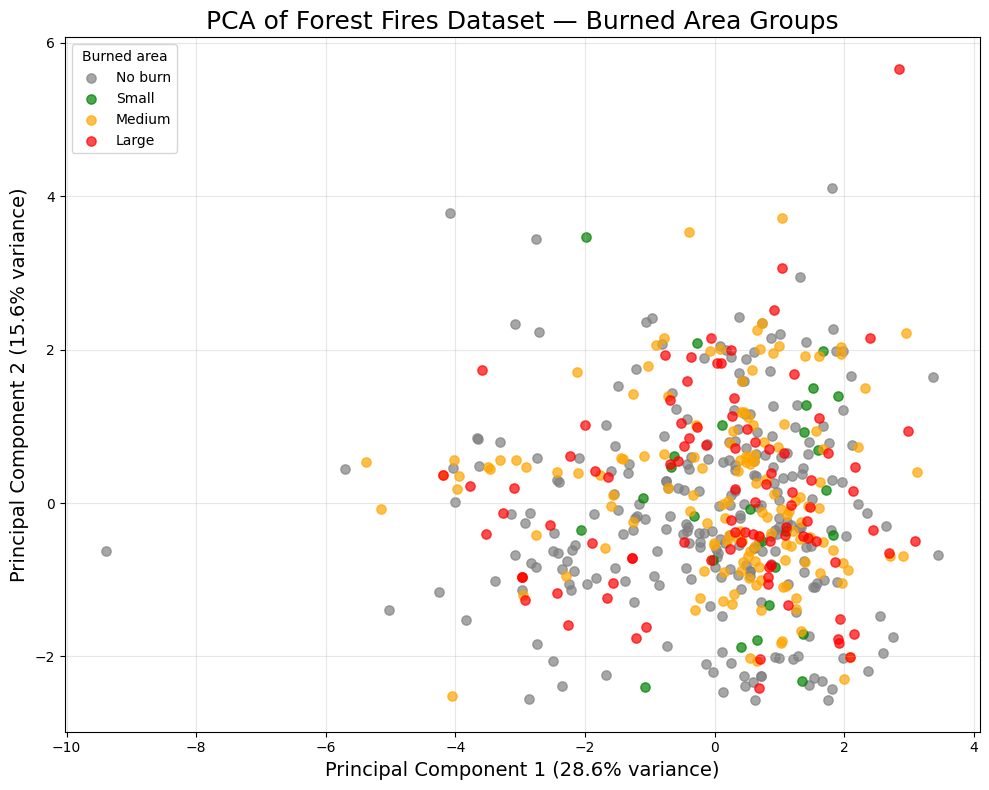

In [ ]:
# Add burned-area groups to the PCA coordinates for plotting
plot_df = pca_df.copy()
plot_df['area_group'] = forest_dataset['area_group'].values

plt.figure(figsize=(10, 8))
plt.xlabel('Principal Component 1 ({:.1%} variance)'.format(pc1_var), fontsize=14)
plt.ylabel('Principal Component 2 ({:.1%} variance)'.format(pc2_var), fontsize=14)
plt.title('PCA of Forest Fires Dataset — Burned Area Groups', fontsize=18)

colors = {
    'No burn': ('gray', 'No burn'),
    'Small': ('green', 'Small'),
    'Medium': ('orange', 'Medium'),
    'Large': ('red', 'Large')
}

for label, (color, name) in colors.items():
    mask = plot_df['area_group'] == label
    plt.scatter(
        plot_df.loc[mask, 'PC1'],
        plot_df.loc[mask, 'PC2'],
        c=color,
        s=45,
        alpha=0.7,
        label=name
    )

plt.legend(title='Burned area')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Step 6 — Feature Contributions

The PCA components are combinations of the original standardized features.
The component loadings below show the contribution of each feature to PC1 and PC2.
The signs indicate direction; the magnitude indicates the strength of the loading.

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=features
)

print('PCA component loadings:')
display(loadings)

PCA component loadings:


,PC1,PC2
X,-0.079167,0.677833
Y,-0.071878,0.670311
FFMC,0.424425,0.061281
DMC,0.429381,0.122725
DC,0.433585,0.012684
ISI,0.359908,0.109792
temp,0.484753,0.015792
RH,-0.231926,0.155478
wind,-0.123841,0.021931
rain,0.049201,0.187857


---
## Summary & Interpretation

- The original 10 numerical predictor features are reduced to 2 principal components.
- The explained variance ratios show how much variation is represented by PC1 and PC2.
- The scatter plot colors observations by burned-area group, but burned area is not an input to PCA.
- The degree of overlap between colors can be used to inspect whether the two components
  visually distinguish observations with different burned areas.

**Important:** PCA is an unsupervised technique. A visual overlap or separation in this plot
does not by itself establish that the weather and spatial features can predict burned area.
The actual explained variance and plot should be examined after running the notebook.